In [1]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
import pandas as pd
from pathlib import Path
from PIL import Image

In [2]:
DATA_DIR = Path("../data/")
OUT_DIR = (DATA_DIR / "processed")

def load_split(name):
    data = np.load(OUT_DIR / f"{name}.npz", allow_pickle=True)
    return normalize(data["X"]), data["y"]
def normalize(X):
    X = X.astype(np.float32)
    mins = X.min(axis=(1,2), keepdims=True)
    maxs = X.max(axis=(1,2), keepdims=True)
    return (X - mins) / (maxs - mins + 1e-8)

x_train, y_train = load_split("train_64")
x_val, y_val = load_split("val_64")
x_test, y_test = load_split("test_64")

In [3]:
# Flatten images to (n, 4096) for sklearn
x_train = x_train.reshape(x_train.shape[0], -1)
x_val = x_val.reshape(x_val.shape[0], -1)
x_test = x_test.reshape(x_test.shape[0], -1)

## Unlimited Ensembled Tree

An Ensemble with no depth or leaf-size limits, to measure overfitting before tuning. Images are flattened from (n, 64, 64) to (n, 4096), since sklearn needs one row per sample (2D).

In [5]:
RFC = RandomForestClassifier(random_state=45)
RFC.fit(x_train, y_train)
print(classification_report(y_train, RFC.predict(x_train)))
print(classification_report(y_val, RFC.predict(x_val)))

              precision    recall  f1-score   support

      glioma       1.00      1.00      1.00      1219
  meningioma       1.00      1.00      1.00      1207
     notumor       1.00      1.00      1.00      1116
   pituitary       1.00      1.00      1.00      1186

    accuracy                           1.00      4728
   macro avg       1.00      1.00      1.00      4728
weighted avg       1.00      1.00      1.00      4728

              precision    recall  f1-score   support

      glioma       0.93      0.87      0.90       181
  meningioma       0.88      0.87      0.87       179
     notumor       0.94      0.99      0.96       165
   pituitary       0.95      0.97      0.96       176

    accuracy                           0.92       701
   macro avg       0.92      0.93      0.92       701
weighted avg       0.92      0.92      0.92       701



### Tuning Phase
Tuned the features, leaves and depths

In [17]:
from sklearn.metrics import f1_score

depths = [20, None]
leaf_sizes = [1, 2, 5]
max_features_list = ["sqrt", "log2", 0.05, 0.1]

results = []

for depth in depths:
    for leaf in leaf_sizes:
        for mf in max_features_list:
            TRFC = RandomForestClassifier(
                n_estimators=300,
                max_features=mf,
                n_jobs=-1,
                max_depth=depth,
                min_samples_leaf=leaf,
                random_state=42,
            )
            TRFC.fit(x_train, y_train)

            train_f1 = f1_score(y_train, TRFC.predict(x_train), average="macro")
            val_f1 = f1_score(y_val, TRFC.predict(x_val), average="macro")

            results.append({
                "max_depth": depth,
                "min_samples_leaf": leaf,
                "max_features": mf,
                "train_f1": round(train_f1, 3),
                "val_f1": round(val_f1, 3),
                "gap": round(train_f1 - val_f1, 3),
            })
results_df = pd.DataFrame(results).sort_values("val_f1", ascending=False)
results_df


,max_depth,min_samples_leaf,max_features,train_f1,val_f1,gap
15,NaN,1,0.1,1.000,0.928,0.072
3,20.0,1,0.1,1.000,0.925,0.075
18,NaN,2,0.05,0.999,0.925,0.074
2,20.0,1,0.05,1.000,0.924,0.076
7,20.0,2,0.1,0.999,0.924,0.075
6,20.0,2,0.05,0.998,0.922,0.076
19,NaN,2,0.1,1.000,0.919,0.080
0,20.0,1,sqrt,1.000,0.918,0.082
1,20.0,1,log2,1.000,0.918,0.082
13,NaN,1,log2,1.000,0.918,0.082


### Tuning number of Trees
After we tuned the leaves, features, and depth we wanted to see if different number of trees made a difference.

In [18]:
best_depth = None
best_leaf = 2
best_mf = 0.05

estimators = [100,200,300,500]
final_results = []

for estimator in estimators:
    ERFC = RandomForestClassifier(
        n_estimators=estimator,
        max_features=best_mf,
        n_jobs=-1,
        min_samples_leaf=best_leaf,
        max_depth=best_depth,
        random_state=42,
    )

    ERFC.fit(x_train, y_train)

    train_f1 = f1_score(y_train, ERFC.predict(x_train), average="macro")
    val_f1 = f1_score(y_val, ERFC.predict(x_val), average="macro")
    final_results.append({
        "estimator": estimator,
        "train_f1": round(train_f1, 3),
        "val_f1": round(val_f1, 3),
        "gap": round(train_f1 - val_f1, 3),
    })

final_results_df = pd.DataFrame(final_results).sort_values("val_f1", ascending=False)
final_results_df



,estimator,train_f1,val_f1,gap
2,300,0.999,0.925,0.074
3,500,0.999,0.922,0.077
0,100,0.999,0.918,0.081
1,200,0.999,0.918,0.081


In [19]:
FRFC = RandomForestClassifier(
    n_estimators=300,
    max_features=0.05,
    n_jobs=-1,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
)
FRFC.fit(x_train, y_train)
print(classification_report(y_test, FRFC.predict(x_test)))

              precision    recall  f1-score   support

      glioma       0.94      0.68      0.79       386
  meningioma       0.83      0.86      0.85       398
     notumor       0.81      0.99      0.89       400
   pituitary       0.94      0.96      0.95       400

    accuracy                           0.87      1584
   macro avg       0.88      0.87      0.87      1584
weighted avg       0.88      0.87      0.87      1584



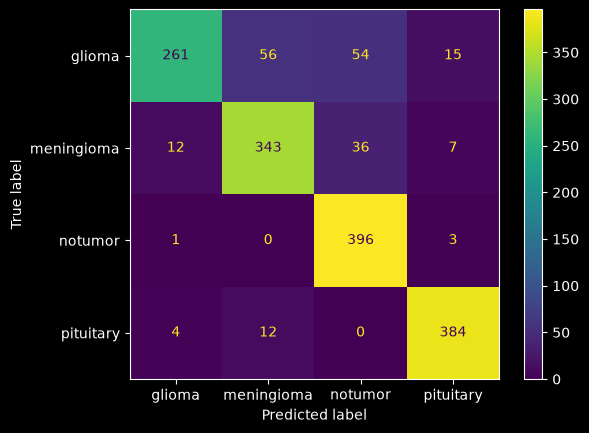

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print(ConfusionMatrixDisplay.from_predictions(y_test, FRFC.predict(x_test)))